In [1]:
import torch
import matplotlib.pyplot as plt

In [2]:
emb = torch.load('model/lm_head.weight.pt')

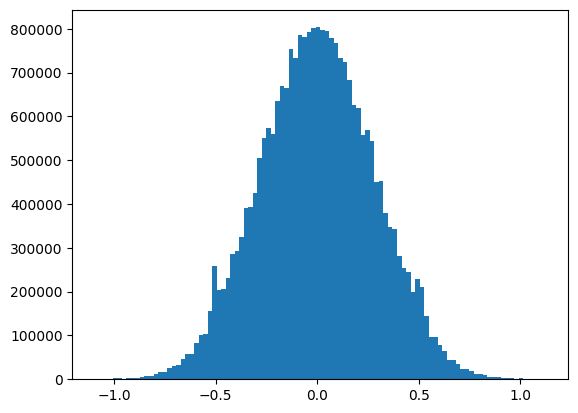

In [4]:
plt.hist(emb.flatten().float(), 100);

In [153]:
emb.shape

torch.Size([50256, 512])

In [154]:
def norm(a):
    return torch.sqrt(torch.sum(a**2)).item()

In [155]:
def similarity(a, b):
    return (a @ b) / (norm(a) * norm(b))

In [229]:
sims = []

for i in range(50256):
    sims.append(similarity(emb[i], emb[9833]).item())
sims = torch.tensor(sims)

In [230]:
torch.sort(sims).indices[-10:]

tensor([ 2273,  8728, 22298, 31309,  4231,  8429, 21975,  9894,  1478,  9833])

In [233]:
import numpy as np
from bpeasy.tokenizer import BPEasyTokenizer

tokenizer = BPEasyTokenizer.from_file("tokenizer.json")
print(tokenizer.decode([21975]))

 governmental


In [212]:
tokenizer.encode("police")

[22298]

In [211]:
from skdim.id import MLE, TwoNN
mle = MLE().fit(emb.float())
twonn = TwoNN().fit(emb.float())
print(mle.dimension_, twonn.dimension_)

nan 73.534778235034


In [198]:
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

X_scaled = StandardScaler().fit_transform(emb.float())

tsne = TSNE(n_components=2, perplexity=5)
X_embedded = tsne.fit_transform(X_scaled)

import plotly.express as px
df = px.data.iris()
fig = px.scatter(x=X_embedded[:, 0], y=X_embedded[:, 1], opacity=1.0, color=np.arange(50256))
fig.update_layout(width=1000, height=800)
fig.show()
